## Projeto "Gestão de Custos de Obras" com Python e Power BI

### Carregando as tabelas

Rode **de cima para baixo**. A célula 2 só funciona depois da célula 1.

In [2]:
import pandas as pd

caminho = r"C:\Users\Augusto\Projeto-1\Construção_Civil\Gestao_Custos_Obras.xlsx"

obras = pd.read_excel(caminho, sheet_name="dObras")
materiais = pd.read_excel(caminho, sheet_name="dMateriais")
orcamento = pd.read_excel(caminho, sheet_name="fOrcamento")
custos = pd.read_excel(caminho, sheet_name="fCustosReais")

print("obras     ", obras.shape)
print("materiais ", materiais.shape)
print("orcamento ", orcamento.shape)
print("custos    ", custos.shape)

obras      (3, 6)
materiais  (9, 6)
orcamento  (27, 5)
custos     (350, 7)


In [3]:
obras

,ID_Obra,Nome_Obra,Localizacao,Gestor,Data_Inicio,Data_Fim_Prevista
0,101,Residencial Horizonte,Rio de Janeiro - RJ,Flávio Brandão,2025-01-15,2026-06-30
1,102,Edifício Jardins,Niterói - RJ,Carlos Silva,2025-03-01,2026-12-15
2,103,Reforma Comercial Centro,Rio de Janeiro - RJ,Ana Souza,2025-05-10,2025-11-30


In [4]:
materiais

,ID_Categoria,Nome_Categoria,ID_Material,Nome_Material,Unidade_Medida,Preco_Base_Unitario
0,1,Estrutura,101,Aço CA-50 10mm,Kg,8.5
1,1,Estrutura,102,Cimento CP II 50kg,Saco,36.0
2,1,Estrutura,103,Concreto Usinado fck 30,m³,380.0
3,2,Alvenaria e Vedação,201,Bloco Cerâmico 9x19x19,Unid,1.8
4,2,Alvenaria e Vedação,202,Argamassa Ensacada 20kg,Saco,18.5
5,3,Instalações Elétricas e Hidráulicas,301,Cabo Flexível 2.5mm²,Metro,3.2
6,3,Instalações Elétricas e Hidráulicas,302,Tubo PVC Esgoto 100mm,Barra 6m,65.0
7,4,Mão de Obra e Serviços,401,Serviço de Pedreiro / Hora,Hora,25.0
8,4,Mão de Obra e Serviços,402,Serviço de Servente / Hora,Hora,15.0


In [5]:
orcamento

,ID_Obra,ID_Material,Quantidade_Orcada,Custo_Unitario_Orcado,Valor_Total_Orcado
0,101,101,1226,8.5,10421.0
1,101,102,960,36.0,34560.0
2,101,103,1394,380.0,529720.0
3,101,201,1230,1.8,2214.0
4,101,202,1195,18.5,22107.5
5,101,301,1144,3.2,3660.8
6,101,302,221,65.0,14365.0
7,101,401,966,25.0,24150.0
8,101,402,1738,15.0,26070.0
9,102,101,430,8.5,3655.0


In [6]:
custos.head(10)

,ID_Transacao,ID_Obra,ID_Material,Data_Pagamento,Quantidade_Realizada,Custo_Unitario_Real,Valor_Total_Real
0,10001,101,402,2025-07-08,80.11,15.57,1247.31
1,10002,101,301,2025-04-13,22.25,3.63,80.77
2,10003,102,402,2025-02-18,15.78,15.14,238.91
3,10004,102,101,2025-02-27,28.19,9.82,276.83
4,10005,103,103,2025-09-08,33.55,433.43,14541.58
5,10006,101,102,2025-05-23,18.59,34.25,636.71
6,10007,103,201,2025-09-02,91.06,2.09,190.32
7,10008,102,201,2025-02-18,90.38,1.76,159.07
8,10009,103,302,2025-02-25,62.57,64.77,4052.66
9,10010,101,401,2025-07-20,57.52,28.81,1657.15


### Checando chaves

In [7]:
obras["ID_Obra"].is_unique
materiais["ID_Material"].is_unique
custos["ID_Transacao"].is_unique

set(orcamento["ID_Obra"]) - set(obras["ID_Obra"])
set(custos["ID_Material"]) - set(materiais["ID_Material"])

set()

## Conferindo a conta

In [8]:
orcamento["check"] = orcamento["Quantidade_Orcada"] * orcamento["Custo_Unitario_Orcado"]
(orcamento["check"] - orcamento["Valor_Total_Orcado"]).abs().max()

custos["check"] = custos["Quantidade_Realizada"] * custos["Custo_Unitario_Real"]
(custos["check"] - custos["Valor_Total_Real"]).abs().max()

np.float64(0.005000000000109139)

### Juntando as tabelas para análise

In [9]:
orc = orcamento.merge(obras, on="ID_Obra").merge(materiais, on="ID_Material")
real = custos.merge(obras, on="ID_Obra").merge(materiais, on="ID_Material")

In [10]:
orcado = orc.groupby(["Nome_Obra", "Nome_Categoria"], as_index=False)["Valor_Total_Orcado"].sum()
realizado = real.groupby(["Nome_Obra", "Nome_Categoria"], as_index=False)["Valor_Total_Real"].sum()
base = orcado.merge(realizado, on=["Nome_Obra", "Nome_Categoria"], how="outer").fillna(0)
base["Desvio"] = base["Valor_Total_Real"] - base["Valor_Total_Orcado"]
base["Desvio_%"] = (base["Desvio"] / base["Valor_Total_Orcado"] * 100).round(2)
base.sort_values("Desvio", ascending=False)

,Nome_Obra,Nome_Categoria,Valor_Total_Orcado,Valor_Total_Real,Desvio,Desvio_%
10,Residencial Horizonte,Instalações Elétricas e Hidráulicas,18025.8,38668.11,20642.31,114.52
4,Reforma Comercial Centro,Alvenaria e Vedação,8855.0,19276.80,10421.80,117.69
0,Edifício Jardins,Alvenaria e Vedação,20164.9,20289.87,124.97,0.62
11,Residencial Horizonte,Mão de Obra e Serviços,50220.0,47435.88,-2784.12,-5.54
6,Reforma Comercial Centro,Instalações Elétricas e Hidráulicas,40443.8,28922.37,-11521.43,-28.49
8,Residencial Horizonte,Alvenaria e Vedação,24321.5,10485.66,-13835.84,-56.89
7,Reforma Comercial Centro,Mão de Obra e Serviços,55025.0,24433.68,-30591.32,-55.60
2,Edifício Jardins,Instalações Elétricas e Hidráulicas,93816.0,55239.39,-38576.61,-41.12
3,Edifício Jardins,Mão de Obra e Serviços,75090.0,34695.92,-40394.08,-53.79
1,Edifício Jardins,Estrutura,578867.0,417745.13,-161121.87,-27.83


In [11]:
base.groupby("Nome_Obra")[["Valor_Total_Orcado", "Valor_Total_Real", "Desvio"]].sum()

,Valor_Total_Orcado,Valor_Total_Real,Desvio
Nome_Obra,,,
Edifício Jardins,767937.9,527970.31,-239967.59
Reforma Comercial Centro,629176.3,365132.32,-264043.98
Residencial Horizonte,667268.3,491060.54,-176207.76


<Axes: xlabel='Nome_Obra'>

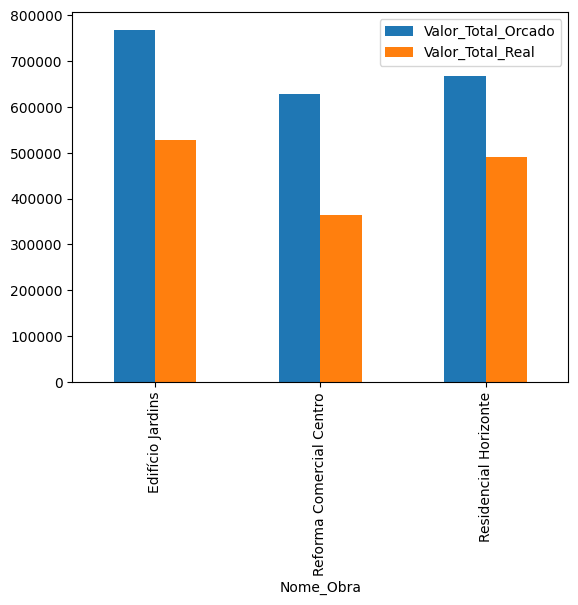

In [12]:
base.groupby("Nome_Obra")[["Valor_Total_Orcado", "Valor_Total_Real"]].sum().plot(kind="bar")

In [13]:
base.sort_values("Desvio_%", ascending=False)

,Nome_Obra,Nome_Categoria,Valor_Total_Orcado,Valor_Total_Real,Desvio,Desvio_%
4,Reforma Comercial Centro,Alvenaria e Vedação,8855.0,19276.80,10421.80,117.69
10,Residencial Horizonte,Instalações Elétricas e Hidráulicas,18025.8,38668.11,20642.31,114.52
0,Edifício Jardins,Alvenaria e Vedação,20164.9,20289.87,124.97,0.62
11,Residencial Horizonte,Mão de Obra e Serviços,50220.0,47435.88,-2784.12,-5.54
1,Edifício Jardins,Estrutura,578867.0,417745.13,-161121.87,-27.83
6,Reforma Comercial Centro,Instalações Elétricas e Hidráulicas,40443.8,28922.37,-11521.43,-28.49
9,Residencial Horizonte,Estrutura,574701.0,394470.89,-180230.11,-31.36
2,Edifício Jardins,Instalações Elétricas e Hidráulicas,93816.0,55239.39,-38576.61,-41.12
5,Reforma Comercial Centro,Estrutura,524852.5,292499.47,-232353.03,-44.27
3,Edifício Jardins,Mão de Obra e Serviços,75090.0,34695.92,-40394.08,-53.79


## Fase 2 — Do pandas ao Power BI

No pandas você **juntou e agregou** numa tabela `base`.
No Power BI você **não recria essa `base` na mão**. Você importa as 4 abas originais, liga as chaves (o equivalente do `merge`) e cria **medidas** (o equivalente do `sum` e do desvio).

Mesma lógica, ferramenta diferente:

| Pandas | Power BI |
|---|---|
| `merge(..., on="ID_Obra")` | relacionamento `dObras[ID_Obra]` para os fatos |
| `groupby(...).sum()` | medida `SUM(...)` + eixo do visual |
| coluna `Desvio` | medida `Desvio = Realizado - Orçado` |

O clique no dashboard (filtrar uma obra) refaz o `groupby` sozinho.


### 2.1 Números de conferência

Antes de abrir o Power BI, grave os totais. Se o cartão do BI não bater com isto, o modelo está errado (relacionamento ou coluna somada).


In [14]:
kpis = pd.Series({
    "Orçado": orcamento["Valor_Total_Orcado"].sum(),
    "Realizado": custos["Valor_Total_Real"].sum(),
})
kpis["Desvio_R$"] = kpis["Realizado"] - kpis["Orçado"]
kpis["Execução_%"] = kpis["Realizado"] / kpis["Orçado"] * 100
kpis["Desvio_%"] = kpis["Desvio_R$"] / kpis["Orçado"] * 100
kpis


Orçado        2.064382e+06
Realizado     1.384163e+06
Desvio_R$    -6.802193e+05
Execução_%    6.704974e+01
Desvio_%     -3.295026e+01
dtype: float64

### 2.2 Por que duas tabelas fato?

`fOrcamento` é o **plano** (sem data de cada gasto).
`fCustosReais` é o **caixa** (cada pagamento tem `Data_Pagamento`).

Por isso:

- cartões Orçado / Realizado / Desvio usam **as duas** fatos, filtradas pelas dimensões;
- gráfico **mensal** só existe para o **realizado** (neste dataset o orçamento não é mês a mês).

Se no BI você arrastar `Data_Pagamento` e a medida Orçado zerar, isso é esperado — não é bug.


### 2.3 Modelo estrela (o que ligar)

Importe **as 4 abas**, não a tabela `base`.

```
           dObras
          /      \
   fOrcamento    fCustosReais
          \      /
          dMateriais
```

Relacionamentos (sempre **1 para muitos**, da dimensão para o fato):

1. `dObras[ID_Obra]` → `fOrcamento[ID_Obra]`
2. `dObras[ID_Obra]` → `fCustosReais[ID_Obra]`
3. `dMateriais[ID_Material]` → `fOrcamento[ID_Material]`
4. `dMateriais[ID_Material]` → `fCustosReais[ID_Material]`

Direção do filtro: da dimensão para o fato (padrão).
Não ligue `fOrcamento` direto em `fCustosReais`. Elas se encontram pelas dimensões, como no seu `merge` duplo.

`ID_Obra` 101 e `ID_Material` 101 são chaves **de tabelas diferentes**. Não misture as colunas.


### 2.4 Medidas (DAX) — o equivalente das colunas do pandas

No Power BI: botão direito na tabela `fCustosReais` (ou numa tabela `_Medidas`) → **Nova medida**.

Crie **uma de cada vez**:

**Orçado** — equivale a `orcamento["Valor_Total_Orcado"].sum()`, mas respeita o filtro (obra, categoria).

```dax
Orçado = SUM(fOrcamento[Valor_Total_Orcado])
```

**Realizado** — soma os pagamentos.

```dax
Realizado = SUM(fCustosReais[Valor_Total_Real])
```

**Desvio** — a mesma ideia de `base["Desvio"]`.

```dax
Desvio = [Realizado] - [Orçado]
```

`DIVIDE` evita erro se o orçado for zero.

```dax
Desvio % = DIVIDE([Desvio], [Orçado])
Execução % = DIVIDE([Realizado], [Orçado])
```

Formate Orçado, Realizado e Desvio como **moeda**; as duas últimas como **porcentagem**.


### 2.5 Páginas do dashboard

**Página 1 — Visão executiva**

- 4 cartões: Orçado, Realizado, Desvio, Execução %
- Barras agrupadas: Orçado vs Realizado por `Nome_Obra`
- Tabela: categoria com Orçado, Realizado, Desvio, Desvio %
- Segmentação: Gestor e/ou Nome_Obra

**Página 2 — Tempo**

- Linha: Realizado por mês (`Data_Pagamento`)
- Título deixando claro: o orçamento não está diluído no calendário

**Página 3 — Detalhe**

- Matriz: obra nas linhas, categoria nas colunas, valor = Desvio %
- Destaque: Instalações no Horizonte e Alvenaria na Reforma (os dois estouros do pandas)

Eixo e legendas vêm das **dimensões** (`Nome_Obra`, `Nome_Categoria`). Valores vêm das **medidas**. Não arraste a coluna `Valor_Total_Orcado` se a medida `Orçado` já existe.


### 2.6 Como conferir se o modelo está certo

1. Cartão **Orçado** ≈ **2.064.382**
2. Cartão **Realizado** ≈ **1.384.163**
3. Clique em Residencial Horizonte: Orçado ≈ **667.268**, Realizado ≈ **491.061**
4. Instalações + Horizonte: Desvio **positivo** (cerca de +20.642)

Se o total geral bater e o filtro de uma obra zerar um cartão, algum relacionamento está invertido ou faltando.


### Checklist no Power BI (nesta ordem)

1. Obter dados → Excel → marcar as 4 planilhas → Carregar
2. Visão **Modelo** → criar as 4 relações
3. Criar as 5 medidas
4. Uma página com 4 cartões + 1 gráfico de barras
5. Conferir os números da seção 2.6
